# Zero-shot test on 93 new simulated materials

The 93 simulated materials downloaded to `/mnt/data/sim_diffraction_gdrive` (analysed in
`diffraction_runs/sim93_analysis/`) were never seen by any model. This notebook tests the simulation model **V** and
the two best mixed models of `6_experimental_test_results.ipynb` (section 8.4), **V_mix2** and **V_mix4b**, on them,
and compares with V's 3 simulation test materials (BW, Co₃(O₂F)₂, SiO₂; "old test"), which these models have not
seen either.

**Setup** (identical to V's simulation test, `eval_sim93.py` → `diffraction_runs/sim93_eval/`):

- 279 new simulations (93 materials × 1, 2, 4 mrad; the angle is read from the probe disk radius, the new `.pkl` files
  are not opened) × thicknesses 20, 40, 100, 200, 500 Å = **1395 patterns**; old test: 45 patterns.
- **Ground truth from py4DSTEM** (`get_maxima_2D` on `dataPots`: sub-pixel `poly`, sigma 0.5, 2 % of the
  strongest peak, minSpacing 4, edgeBoundary 2, no peak cap; precomputed by `make_gt_py4dstem.py`, read by
  `benchmark_diffraction.ground_truth`); weak peaks = the same at 1 %; direct beam removed.
- Input `log1p(1000 · img / max)`;
  **targets = visible spots** (3 × 3 maximum of `dataMeas` ≥ 10⁻⁴ of the pattern maximum); matching within 3 px.
- **Thresholds.** The 93 new materials are split by material (seed 0) into **31 validation** materials, where
  thresholds are chosen (grid 0.05–0.80), and **62 test** materials, where they are scored (`threshold_sim93.py`).
  Three rules (section 1):
  - **goal** (used from section 2 on): find as many visible spots as possible with few truly false detections.
    Chosen by the largest *net found* = (visible spots found − truly false detections) / visible spots, i.e. every
    truly false detection cancels one found spot. Detections on a weaker real peak (1–2 % `dataPots`) or 3–5 px from
    a missed spot are not counted against it.
  - **f1**: the largest F1, where every false detection counts (also those on weak peaks or near a spot).
  - **usual**: the threshold each model already had (V_mix2 0.48 and V_mix4b 0.46 from notebook 6, 8.4, chosen on
    experimental validation patterns; V 0.572, its own simulation threshold).

  **Sections 2–5 use the goal thresholds and score only the 62 new test materials** (and the 3 old test materials),
  so no score comes from materials the threshold was chosen on.
- Intensity-weighted accuracy (notebook 6, section 9) in two forms: weights from the **image** (`dataMeas`, as in
  notebook 6) and from **`dataPots`** (each spot's own strength; no light from the direct beam).
- New materials have no names here; they are called by the first 8 characters of their folder.

In [1]:
import json, sys
from pathlib import Path
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LogNorm
from spotiflow.utils.matching import points_matching

sys.path.insert(0, ".")
import benchmark_diffraction as bd
from intensity_accuracy import weighted_accuracy

BLUE, SKY, ORANGE, YELLOW, PINK = "#0072B2", "#56B4E9", "#E69F00", "#F0E442", "#CC79A7"
STYLE = {"V": (SKY, "^"), "V_mix2": (PINK, "D"), "V_mix4b": (ORANGE, "s")}
GRAY = plt.get_cmap("gray").copy(); GRAY.set_bad("black")
E = Path("diffraction_runs/sim93_eval")
S = json.loads((E / "settings.json").read_text())
MODELS = S["models"]
meta = pd.read_csv(E / "patterns.csv").set_index("pattern")
split = json.loads((E / "threshold_split.json").read_text())
RULES = {r: split[f"{r}_thresholds"] for r in ("goal", "f1", "usual")}
THR = RULES["goal"]                                                   # used from section 2 on
at = pd.read_csv(E / "at_threshold.csv").join(meta.drop(columns=["n_vis"]), on="pattern")
at["set"] = at.part.map({"val": "new validation (31)", "test": "new test (62)", "old test": "old test"})
one = at[(at.rule == "goal") & (at.part != "val")].copy()
one["dataset"] = one.part.map({"test": "new", "old test": "old test"})
wide = pd.read_csv(E / "sweep_wide.csv.gz").join(meta.drop(columns=["n_vis"]), on="pattern")
wide["set"] = np.where(wide.material.isin(split["val"]), "new validation (31)",
                       np.where(wide.material.isin(split["test"]), "new test (62)", "old test"))
PRED = np.load(E / "predictions.npz")
ROOTS_OLD = json.loads(Path("diffraction_runs/ft_V/split.json").read_text())["args"]["root"]
OLD_DIRS = {f.name: f for f in bd.find_material_folders(ROOTS_OLD)}
NEW_ROOT = Path("/mnt/data/sim_diffraction_gdrive")


def pooled(d):
    t = d[["n_vis", "found_vis", "n_pred", "false", "truly_false", "false_on_weak_peak", "false_near_spot"]].sum()
    P, R = 1 - t["false"] / max(t.n_pred, 1), t.found_vis / max(t.n_vis, 1)
    out = dict(patterns=len(d), visible=int(t.n_vis), found=int(t.found_vis), false=int(t["false"]),
               truly_false=int(t.truly_false), truly_false_share=t.truly_false / max(t.n_pred, 1),
               net_found=(t.found_vis - t.truly_false) / max(t.n_vis, 1),
               precision=P, recall=R, f1=2 * P * R / (P + R) if P + R else 0)
    if "acc_img" in d and d.acc_img.notna().any():
        out.update(acc_img=d.acc_img.mean(), acc_pots=d.acc_pots.mean())
    return pd.Series(out)


def load(i):
    r = meta.loc[i]
    folder = NEW_ROOT / r.folder if r.dataset == "new" else OLD_DIRS[r.folder]
    with h5py.File(folder / f"{r.uid}_training.h5", "r") as h:
        ti = int(np.where(h["thicknesses"][:] == r.thickness)[0][0])
        img, pots, probe = h["dataMeas"][..., ti], h["dataPots"][..., ti], h["dataProbe"][:]
    return img, pots, probe, bd.ground_truth(img, pots, bd.disk_radius(probe), S["vis_box"])


def pred(k, i, t=None):
    p, pr = PRED[f"{k}_{i}_pts"], PRED[f"{k}_{i}_prob"]
    return p[pr >= (THR[k] if t is None else t)]


print("thresholds:", RULES)
print(meta.groupby(["dataset", "angle"]).size().unstack())

/home/ubuntu/micromamba/envs/spotiflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


thresholds: {'goal': {'V': 0.19, 'V_mix2': 0.23, 'V_mix4b': 0.24}, 'f1': {'V': 0.17, 'V_mix2': 0.18, 'V_mix4b': 0.2}, 'usual': {'V': 0.572, 'V_mix2': 0.48, 'V_mix4b': 0.46}}
angle     1.0  2.0  4.0
dataset                
new       465  465  465
old test   15   15   15


## 1. Thresholds and overall scores

Left: the goal score *net found* against the threshold on the new validation materials (dotted), the new test
materials (solid) and the old test (dashed). Middle: F1. Right: visible recall against the share of detections that
are truly false. Markers: filled = goal threshold, half-filled = f1 threshold, open = usual threshold. The table
pools all patterns of each set and adds the intensity-weighted accuracy (mean over patterns; weights from the image
and from `dataPots`). The oracle row (best net found on the new test materials themselves) is an upper bound, not a
fair score.

threshold  recall  truly_false_share  \
set           model   rule                                                  
new test (62) V       goal               0.190   0.407              0.127   
                      f1                 0.170   0.427              0.137   
                      usual              0.572   0.140              0.013   
                      oracle (goal)      0.170   0.427              0.137   
              V_mix2  goal               0.230   0.378              0.139   
                      f1                 0.180   0.404              0.153   
                      usual              0.480   0.241              0.071   
                      oracle (goal)      0.200   0.394              0.147   
              V_mix4b goal               0.240   0.382              0.144   
                      f1                 0.200   0.405              0.157   
                      usual              0.460   0.264              0.084   
                      oracle (goal)      0.220   0.394              0.150   
old test      V       goal               0.190   0.641              0.189   
                      f1                 0.170   0.651              0.204   
                      usual              0.572   0.436              0.000   
              V_mix2  goal               0.230   0.648              0.105   
                      f1                 0.180   0.659              0.131   
                      usual              0.480   0.576              0.023   
              V_mix4b goal               0.240   0.639              0.103   
                      f1                 0.200   0.650              0.125   
                      usual              0.460   0.585              0.032   

                                     net_found  precision     f1  acc_img  \
set           model   rule                                                  
new test (62) V       goal               0.306      0.565  0.473    0.515   
                      f1                 0.308      0.545  0.479    0.513   
                      usual              0.138      0.889  0.242    0.658   
                      oracle (goal)      0.308      0.545  0.479      NaN   
              V_mix2  goal               0.276      0.557  0.450    0.587   
                      f1                 0.278      0.529  0.458    0.578   
                      usual              0.216      0.718  0.361    0.619   
                      oracle (goal)      0.278      0.541  0.456      NaN   
              V_mix4b goal               0.270      0.544  0.449    0.590   
                      f1                 0.270      0.521  0.456    0.586   
                      usual              0.229      0.680  0.381    0.607   
                      oracle (goal)      0.271      0.533  0.453      NaN   
old test      V       goal               0.426      0.641  0.641    0.702   
                      f1                 0.403      0.611  0.630    0.698   
                      usual              0.436      0.993  0.606    0.830   
              V_mix2  goal               0.552      0.771  0.704    0.820   
                      f1                 0.529      0.726  0.691    0.811   
                      usual              0.561      0.920  0.709    0.846   
              V_mix4b goal               0.545      0.776  0.701    0.810   
                      f1                 0.527      0.736  0.691    0.792   
                      usual              0.563      0.902  0.710    0.842   

                                     acc_pots   visible     found  \
set           model   rule                                          
new test (62) V       goal              0.667  236789.0   96389.0   
                      f1                0.664  236789.0  101124.0   
                      usual             0.639  236789.0   33112.0   
                      oracle (goal)       NaN  236789.0  101124.0   
              V_mix2  goal              0.659  236789.0   89424.0   
          

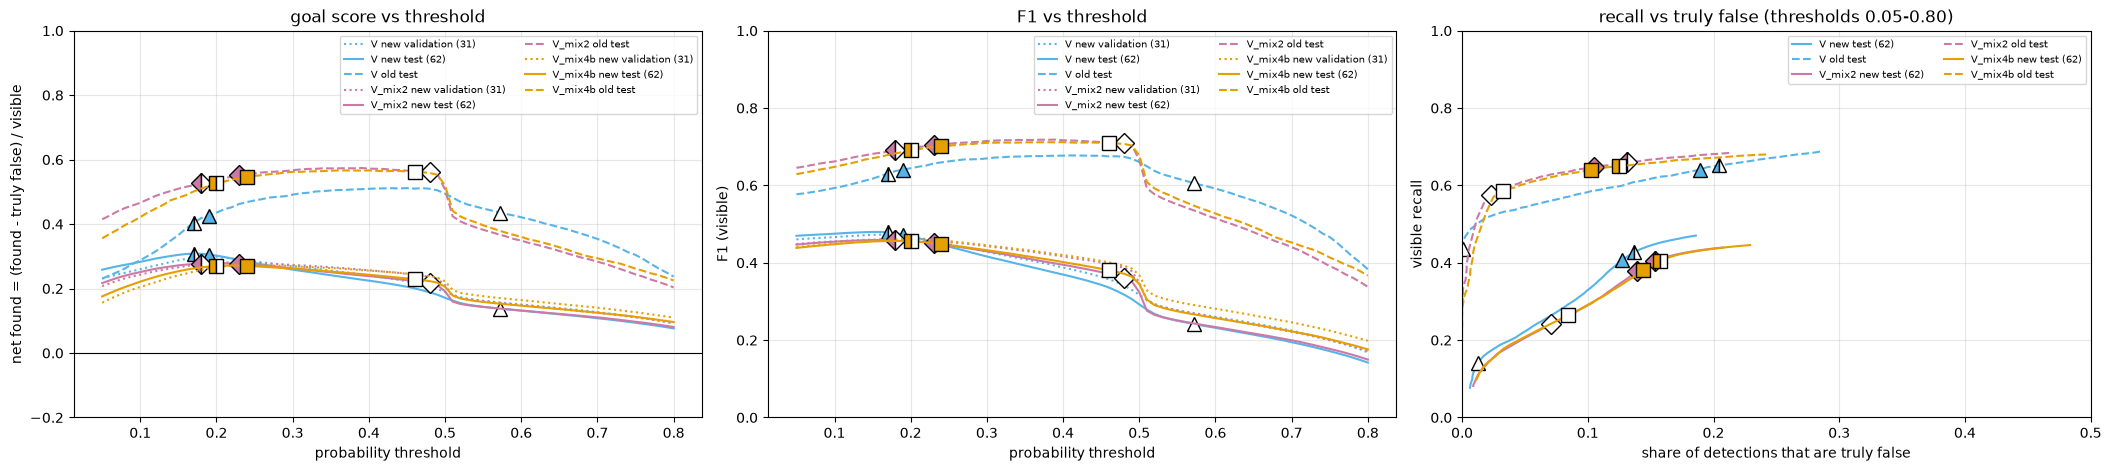

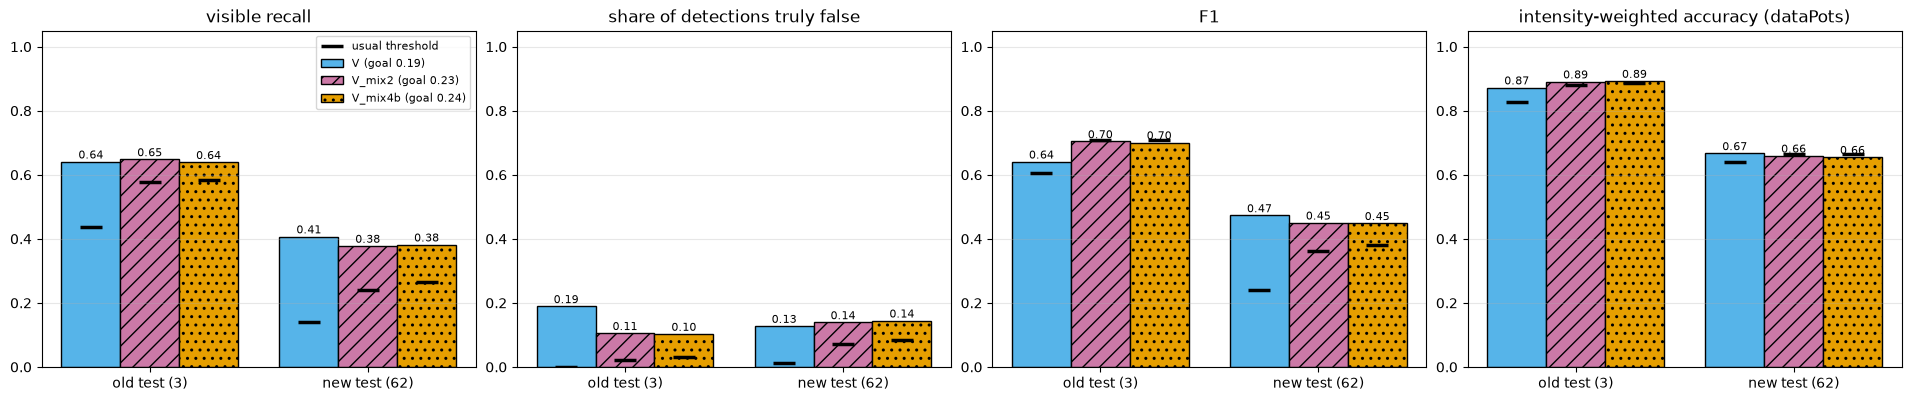

In [2]:
curve = wide.groupby(["model", "set", "threshold"]).apply(pooled)
tab = at[at.part != "val"].groupby(["set", "model", "rule"]).apply(pooled)
tab.insert(0, "threshold", at[at.part != "val"].groupby(["set", "model", "rule"]).threshold.first())
orc = []
for k in MODELS:
    te = curve.loc[(k, "new test (62)")]
    orc.append(dict(set="new test (62)", model=k, rule="oracle (goal)", threshold=te.net_found.idxmax(),
                    **te.loc[te.net_found.idxmax()].to_dict()))
tab = pd.concat([tab, pd.DataFrame(orc).set_index(["set", "model", "rule"])]).sort_index()
tab = tab.reindex(["goal", "f1", "usual", "oracle (goal)"], level="rule")
display(tab[["threshold", "recall", "truly_false_share", "net_found", "precision", "f1", "acc_img", "acc_pots",
             "visible", "found", "truly_false", "false"]].round(3))

fig, axs = plt.subplots(1, 3, figsize=(21, 4.6), constrained_layout=True)
for k in MODELS:
    c, mk = STYLE[k]
    for part, ls in (("new validation (31)", ":"), ("new test (62)", "-"), ("old test", "--")):
        f = curve.loc[(k, part)]
        axs[0].plot(f.index, f.net_found, ls, color=c, label=f"{k} {part}")
        axs[1].plot(f.index, f.f1, ls, color=c, label=f"{k} {part}")
        if part != "new validation (31)":
            axs[2].plot(f.truly_false_share, f.recall, ls, color=c, label=f"{k} {part}")
    for part in ("new test (62)", "old test"):
        for rule in ("goal", "f1", "usual"):
            r_ = tab.loc[(part, k, rule)]
            kw = dict(marker=mk, ms=10, mec="black", ls="none", mfc=c if rule != "usual" else "white",
                      fillstyle="left" if rule == "f1" else "full", markerfacecoloralt="white")
            axs[0].plot(r_.threshold, r_.net_found, **kw)
            axs[1].plot(r_.threshold, r_.f1, **kw)
            axs[2].plot(r_.truly_false_share, r_.recall, **kw)
axs[0].set(xlabel="probability threshold", ylabel="net found = (found - truly false) / visible", ylim=(-0.2, 1),
           title="goal score vs threshold")
axs[0].axhline(0, color="black", lw=0.8)
axs[1].set(xlabel="probability threshold", ylabel="F1 (visible)", ylim=(0, 1), title="F1 vs threshold")
axs[2].set(xlabel="share of detections that are truly false", ylabel="visible recall", xlim=(0, 0.5), ylim=(0, 1),
           title="recall vs truly false (thresholds 0.05-0.80)")
for ax in axs:
    ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.show()

fig, axs = plt.subplots(1, 4, figsize=(19, 3.9), constrained_layout=True)
for ax, col in zip(axs, ["recall", "truly_false_share", "f1", "acc_pots"]):
    x = np.arange(2)
    for j, k in enumerate(MODELS):
        c, _ = STYLE[k]
        v = [tab.loc[(d, k, "goal"), col] for d in ("old test", "new test (62)")]
        u = [tab.loc[(d, k, "usual"), col] for d in ("old test", "new test (62)")]
        ax.bar(x + (j - 1) * 0.27, v, 0.27, color=c, edgecolor="black", hatch=["", "//", ".."][j], label=f"{k} (goal {THR[k]:.2f})")
        ax.plot(x + (j - 1) * 0.27, u, marker="_", ms=16, mew=2.5, color="black", ls="none",
                label="usual threshold" if j == 0 else None)
        for xi, vi in zip(x + (j - 1) * 0.27, v):
            ax.text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=8)
    ax.set_xticks(x, ["old test (3)", "new test (62)"])
    ax.set(ylim=(0, 1.05), title={"recall": "visible recall", "truly_false_share": "share of detections truly false", "f1": "F1",
                                  "acc_pots": "intensity-weighted accuracy (dataPots)"}[col])
    ax.grid(alpha=0.3, axis="y")
axs[0].legend(fontsize=8, loc="upper right")
plt.show()

## 2. By probe angle, thickness and disk overlap

Visible recall, precision and the intensity-weighted accuracy (weights from `dataPots` and from the image) of each
model (goal thresholds) on the 62 new test materials (solid lines) and the old test (dashed). Recall and precision
are pooled per bin, the accuracy is the mean over the bin's patterns. Overlap ratio η = 2r / s (disk diameter /
spot spacing): < 0.85 separate, 0.85–1.7 touching, > 1.7 overlapping.

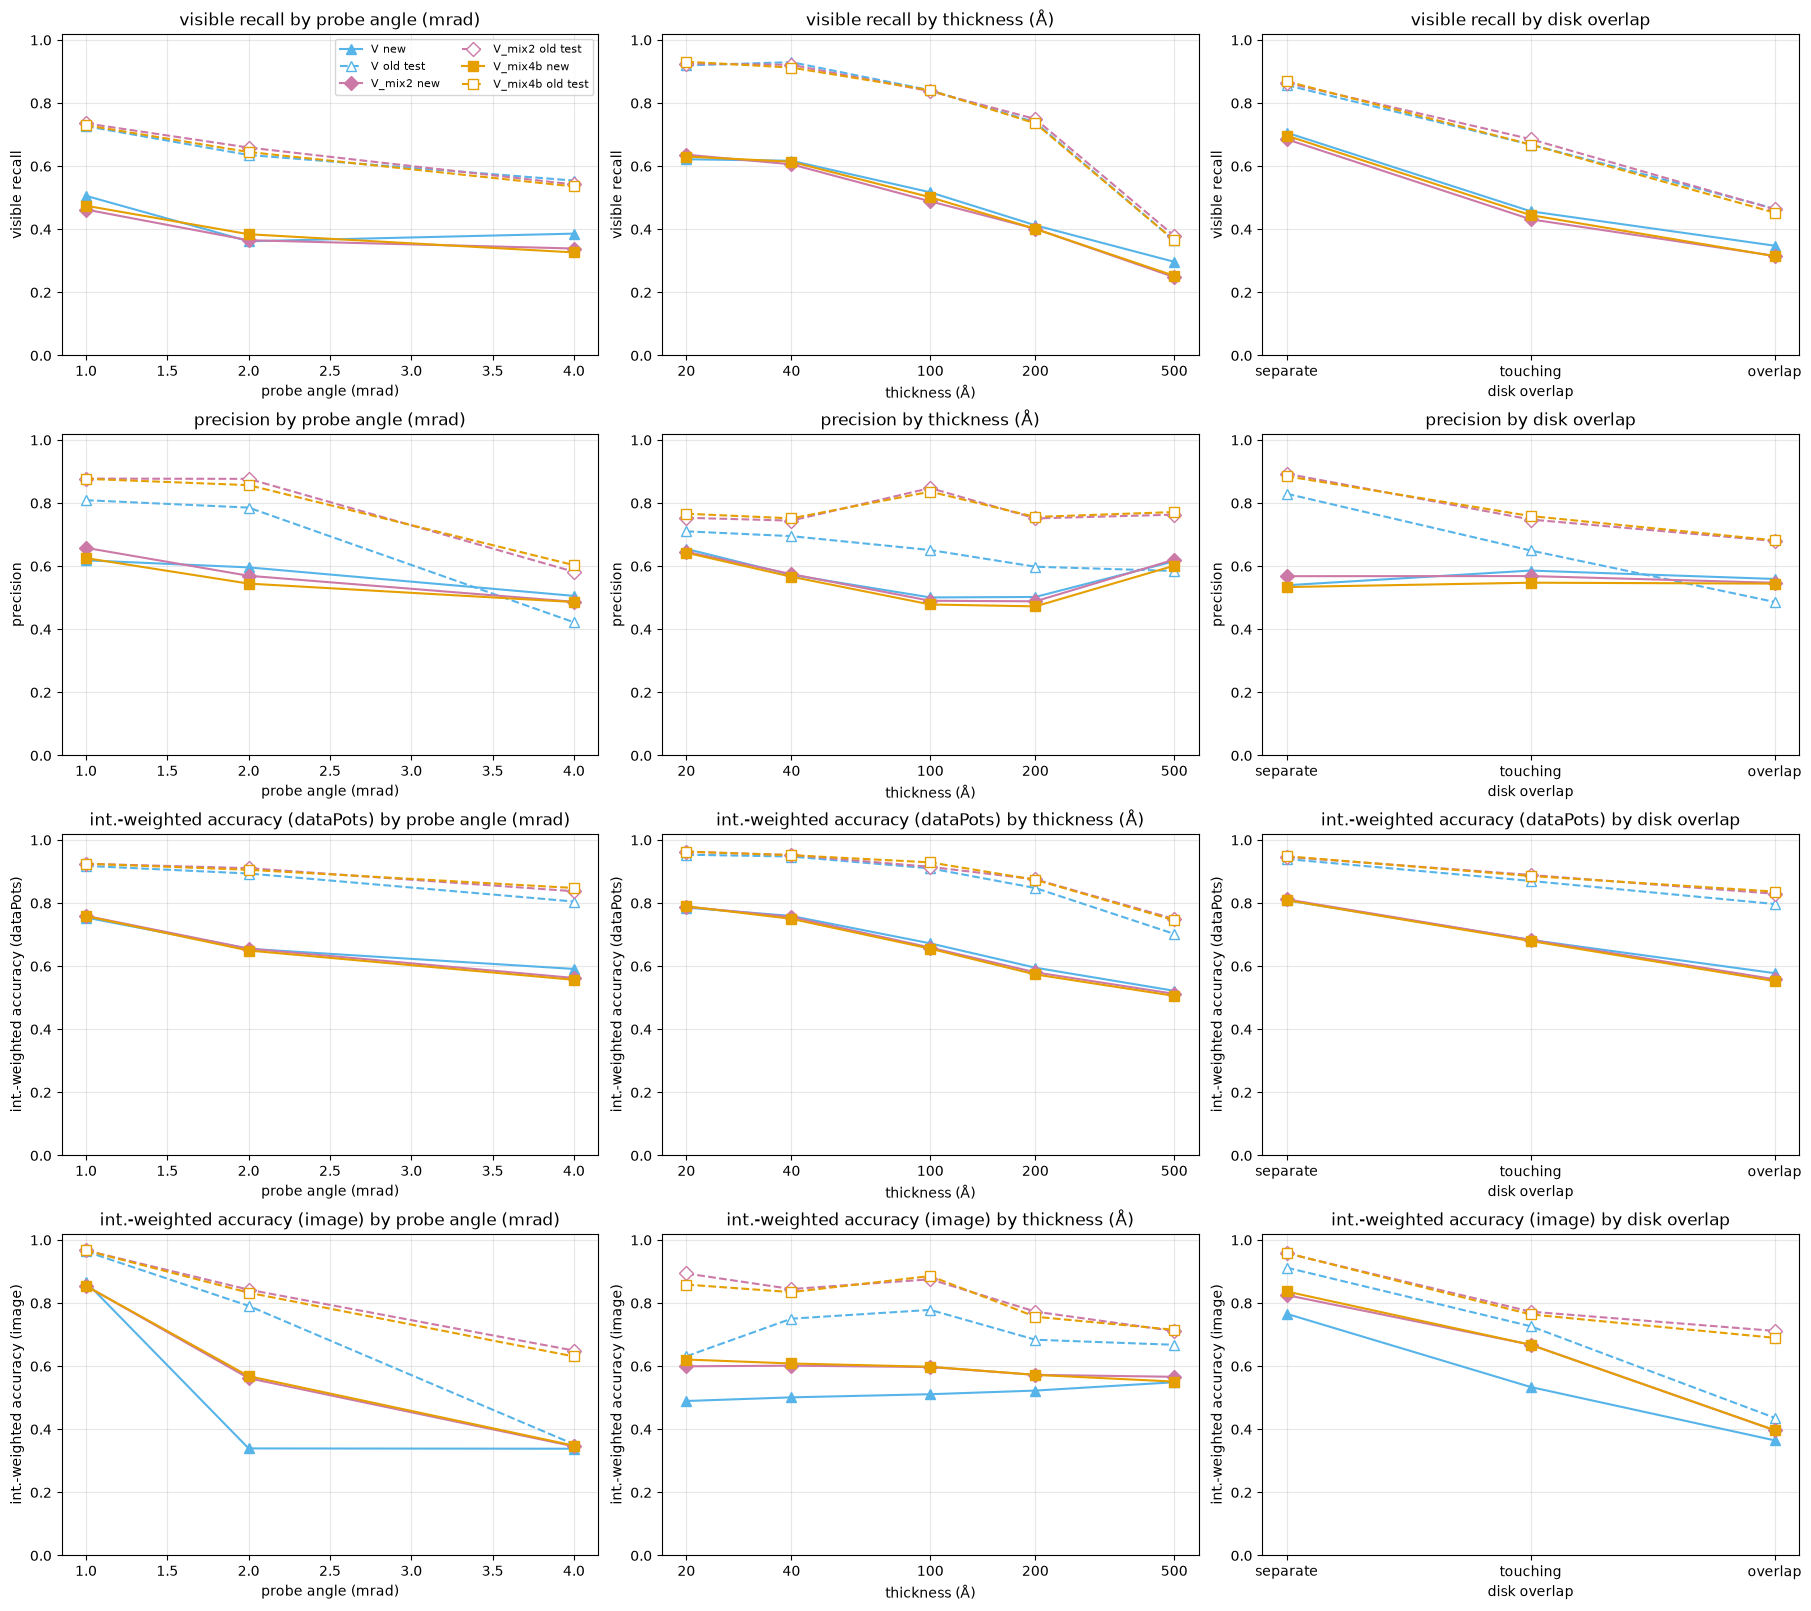

V_mix2, new test materials, by angle x thickness: visible recall


thickness,20.0,40.0,100.0,200.0,500.0
angle,,,,,
1.0,0.894,0.852,0.709,0.510,0.298
2.0,0.639,0.610,0.463,0.393,0.241
4.0,0.560,0.512,0.403,0.347,0.219


V_mix2, new test materials, by angle x thickness: intensity-weighted accuracy (dataPots)


thickness,20.0,40.0,100.0,200.0,500.0
angle,,,,,
1.0,0.905,0.891,0.781,0.670,0.550
2.0,0.803,0.759,0.647,0.564,0.505
4.0,0.658,0.618,0.549,0.507,0.481


In [3]:
one = one.assign(regime=pd.cut(one.eta, [0, 0.85, 1.7, 99], labels=["separate", "touching", "overlap"]))
ROWS2 = [("recall", "visible recall"), ("precision", "precision"), ("acc_pots", "int.-weighted accuracy (dataPots)"),
         ("acc_img", "int.-weighted accuracy (image)")]
fig, axs = plt.subplots(len(ROWS2), 3, figsize=(18, 4 * len(ROWS2)), constrained_layout=True)
for col_i, (by, lab) in enumerate((("angle", "probe angle (mrad)"), ("thickness", "thickness (Å)"), ("regime", "disk overlap"))):
    for k in MODELS:
        c, mk = STYLE[k]
        for d, ls in (("new", "-"), ("old test", "--")):
            g = one[(one.model == k) & (one.dataset == d)].groupby(by, observed=True).apply(pooled)
            xs = g.index.astype(str) if by == "regime" else g.index
            for r_, (col, _) in enumerate(ROWS2):
                axs[r_, col_i].plot(xs, g[col], ls, color=c, marker=mk, ms=7, mfc=c if d == "new" else "white", label=f"{k} {d}")
    for r_, (_, name) in enumerate(ROWS2):
        axs[r_, col_i].set(xlabel=lab, ylabel=name, ylim=(0, 1.02), title=f"{name} by {lab}")
        axs[r_, col_i].grid(alpha=0.3)
        if by == "thickness":
            axs[r_, col_i].set_xscale("log"); axs[r_, col_i].set_xticks([20, 40, 100, 200, 500], ["20", "40", "100", "200", "500"])
            axs[r_, col_i].set_xticks([], minor=True)
axs[0, 0].legend(fontsize=8, ncol=2)
plt.show()
g2 = one[(one.model == "V_mix2") & (one.dataset == "new")].groupby(["angle", "thickness"]).apply(pooled)
print("V_mix2, new test materials, by angle x thickness: visible recall")
display(g2.recall.unstack().round(3))
print("V_mix2, new test materials, by angle x thickness: intensity-weighted accuracy (dataPots)")
display(g2.acc_pots.unstack().round(3))

## 3. Why recall drops: how bright are the missed spots?

A spot counts as *visible* when its 3 × 3 maximum in `dataMeas` reaches 10⁻⁴ of the pattern maximum. The model
sees `log1p(1000 · img / max)`: a spot at 10⁻⁴ of the maximum is 0.095 in the input, against 6.9 for the direct beam,
i.e. practically black. In the new, weakly scattering materials (the direct beam keeps 75 % of the intensity, against
34 % in the 24 training materials, `sim93_analysis`) many labelled spots are that faint.

Below (goal thresholds; new test materials and old test): for every visible spot, its brightness *b* = 3 × 3 maximum / pattern maximum, and whether the model found it.
If the recall **at a given brightness** is the same for the new and the old materials, the models generalise and
the lower overall recall comes from the larger share of faint spots. (This section looks at single spots, found or
not; the intensity-weighted accuracy is a per-pattern score and is shown in sections 1, 2, 4 and 5.)

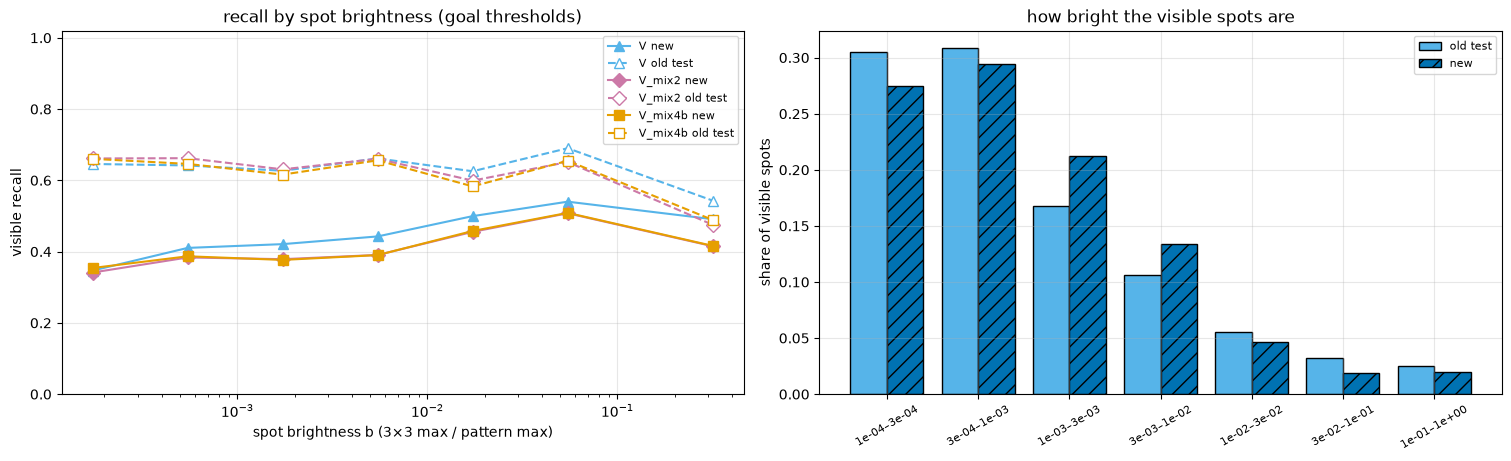

visible recall when only spots brighter than b are required:


b ≥ 0.0001  b ≥ 0.001  b ≥ 0.003  b ≥ 0.01  \
dataset  model                                                 
new      V             0.408      0.445      0.468     0.507   
         V_mix2        0.378      0.398      0.417     0.458   
         V_mix4b       0.382      0.397      0.417     0.459   
old test V             0.641      0.636      0.643     0.626   
         V_mix2        0.648      0.626      0.622     0.587   
         V_mix4b       0.639      0.617      0.618     0.583   

                  share of spots with b < 1e-3  
dataset  model                                  
new      V                               0.569  
         V_mix2                          0.569  
         V_mix4b                         0.569  
old test V                               0.614  
         V_mix2                          0.614  
         V_mix4b                         0.614

In [4]:
spot_rows = []
for i in sorted(one.pattern.unique()):
    img, pots, probe, g = load(i)
    vis = g["visible"]
    pts = g["points"][vis].astype(float)
    pix = np.clip(np.round(pts).astype(int), 0, np.array(img.shape) - 1)
    b = bd.maximum_filter(img, size=3)[pix[:, 0], pix[:, 1]] / img.max()
    for k in MODELS:
        p = pred(k, i)
        p = p[bd.far_from(p, g["beam"], bd.BEAM_R)]
        found = np.zeros(len(pts), bool)
        if len(p) and len(pts):
            found[[a for a, _ in points_matching(pts, p, cutoff_distance=bd.CUTOFF).matched_pairs]] = True
        spot_rows.append(pd.DataFrame(dict(model=k, pattern=i, dataset="new" if meta.loc[i, "dataset"] == "new" else "old test", angle=meta.loc[i, "angle"],
                                           thickness=meta.loc[i, "thickness"], b=b, found=found)))
spots = pd.concat(spot_rows, ignore_index=True)
BINS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 1.01]
spots["bin"] = pd.cut(spots.b, BINS, include_lowest=True)
centre = np.sqrt(np.array(BINS[:-1]) * np.array(BINS[1:]))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
for k in MODELS:
    c, mk = STYLE[k]
    for d, ls in (("new", "-"), ("old test", "--")):
        r_ = spots[(spots.model == k) & (spots.dataset == d)].groupby("bin", observed=False).found.mean()
        axs[0].plot(centre, r_.values, ls, color=c, marker=mk, ms=7, mfc=c if d == "new" else "white", label=f"{k} {d}")
sh = spots[spots.model == MODELS[0]].groupby(["dataset", "bin"], observed=False).size().unstack(0)
sh = sh / sh.sum()
for j, (d, c, h) in enumerate((("old test", SKY, ""), ("new", BLUE, "//"))):
    axs[1].bar(np.arange(len(centre)) + (j - 0.5) * 0.4, sh[d].values, 0.4, color=c, edgecolor="black", hatch=h, label=d)
axs[0].set(xscale="log", xlabel="spot brightness b (3×3 max / pattern max)", ylabel="visible recall", ylim=(0, 1.02),
           title="recall by spot brightness (goal thresholds)")
axs[1].set_xticks(np.arange(len(centre)), [f"{lo:.0e}–{hi:.0e}" for lo, hi in zip(BINS[:-1], BINS[1:])], rotation=30, fontsize=8)
axs[1].set(ylabel="share of visible spots", title="how bright the visible spots are")
for ax in axs:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

# recall if spots fainter than a brightness cut are not required
cuts = [1e-4, 1e-3, 3e-3, 1e-2]
rc = pd.DataFrame({f"b ≥ {c:g}": spots[spots.b >= c].groupby(["dataset", "model"]).found.mean() for c in cuts})
rc["share of spots with b < 1e-3"] = spots.assign(f=spots.b < 1e-3).groupby(["dataset", "model"]).f.mean()
print("visible recall when only spots brighter than b are required:")
display(rc.reindex(MODELS, level="model").round(3))

## 4. Per material

F1 and intensity-weighted accuracy (`dataPots` weights, mean over the material's patterns) of each of the 62 new test
materials (3 angles × 5 thicknesses, goal thresholds), with the old test materials for comparison (black lines,
V_mix2).

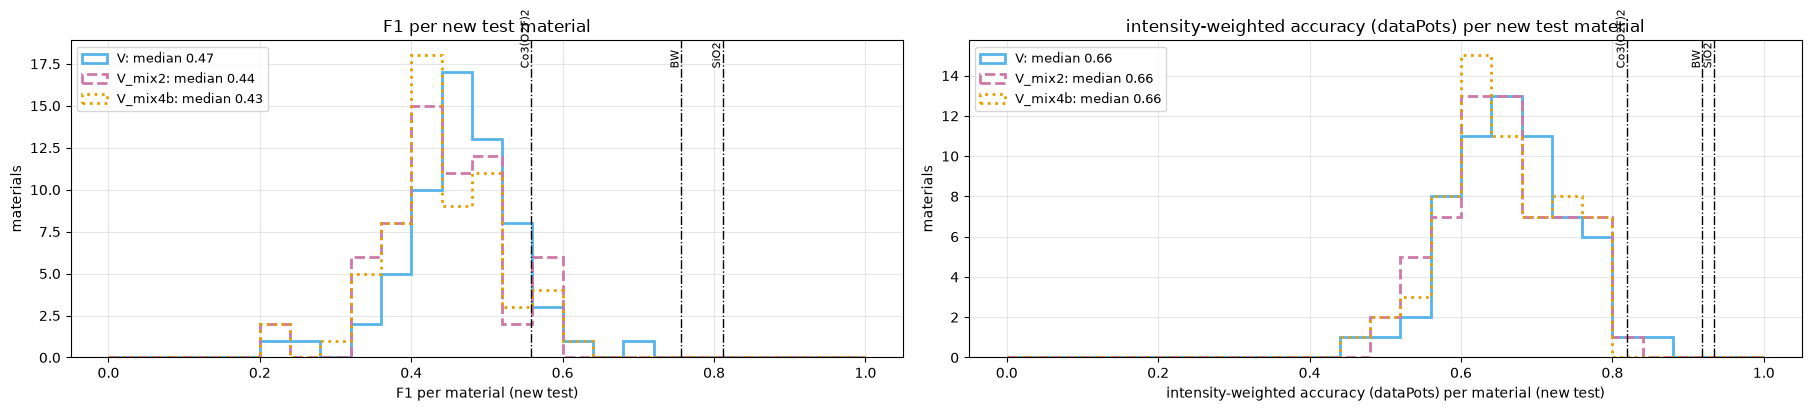

V_mix2: the 8 worst and the 8 best new test materials (by F1)


,f1,recall,precision,acc_pots,acc_img,beam_share,eta,n_vis
material,,,,,,,,
90c8072f,0.219,0.607,0.134,0.543,0.436,0.847,0.354,30.0
e5f400f1,0.224,0.529,0.142,0.538,0.249,0.984,0.959,16.0
90d4c677,0.330,0.212,0.740,0.654,0.587,0.970,2.316,201.0
e5b7c60a,0.339,0.246,0.546,0.599,0.545,0.573,1.618,259.0
3ad047c1,0.344,0.471,0.271,0.651,0.421,0.938,0.908,39.0
3abcf766,0.346,0.257,0.531,0.659,0.581,0.650,1.391,277.0
e58d747d,0.349,0.339,0.359,0.594,0.668,0.783,1.183,110.0
90744c67,0.354,0.308,0.416,0.494,0.470,0.696,1.315,131.0
3b2499a8,0.599,0.554,0.652,0.617,0.571,0.854,1.667,234.0


Spearman correlation of per-material F1 (V_mix2) with: {'beam_share': -0.03, 'eta': 0.08, 'n_vis': 0.1}


In [5]:
per = one.groupby(["model", "dataset", "material"]).apply(pooled)
fig, axs = plt.subplots(1, 2, figsize=(18, 4), constrained_layout=True)
bins = np.linspace(0, 1, 26)
for ax, col, name in ((axs[0], "f1", "F1"), (axs[1], "acc_pots", "intensity-weighted accuracy (dataPots)")):
    for j, k in enumerate(MODELS):
        c, _ = STYLE[k]
        ax.hist(per.loc[(k, "new")][col], bins=bins, histtype="step", lw=2, color=c, ls=["-", "--", ":"][j],
                label=f"{k}: median {per.loc[(k, 'new')][col].median():.2f}")
    for m_, f in per.loc[("V_mix2", "old test")][col].items():
        ax.axvline(f, color="black", lw=1, ls="-.")
        ax.text(f, ax.get_ylim()[1] * 0.92, m_, rotation=90, fontsize=8, ha="right")
    ax.set(xlabel=f"{name} per material (new test)", ylabel="materials", title=f"{name} per new test material")
    ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="upper left")
plt.show()
pm = per.loc[("V_mix2", "new")].join(meta[meta.dataset == "new"].groupby("material")[["beam_share", "eta", "n_vis"]].median())
print("V_mix2: the 8 worst and the 8 best new test materials (by F1)")
display(pd.concat([pm.nsmallest(8, "f1"), pm.nlargest(8, "f1")])[["f1", "recall", "precision", "acc_pots", "acc_img",
                                                                  "beam_share", "eta", "n_vis"]].round(3))
print("Spearman correlation of per-material F1 (V_mix2) with:",
      pm[["beam_share", "eta", "n_vis"]].corrwith(pm.f1, method="spearman").round(2).to_dict())

## 5. Example predictions

V_mix2 and V_mix4b (goal thresholds) on new test materials at 100 Å: for each angle the material with the median
V_mix2 F1 at that angle, and one of the worst. Left: `dataMeas` (log, from the visibility floor to the maximum), then the model input, then
the two models. Markers as in notebook 6, section 6:

| marker | meaning |
|---|---|
| ○ light blue | found, visible |
| ◇ white | found, not visible |
| ✕ orange | missed, visible |
| ⬡ light blue, dashed | false, near a real spot (a missed candidate 3–5 px away) |
| □ orange | false, on a weaker 1–2 % `dataPots` peak |
| △ yellow | false, truly false |

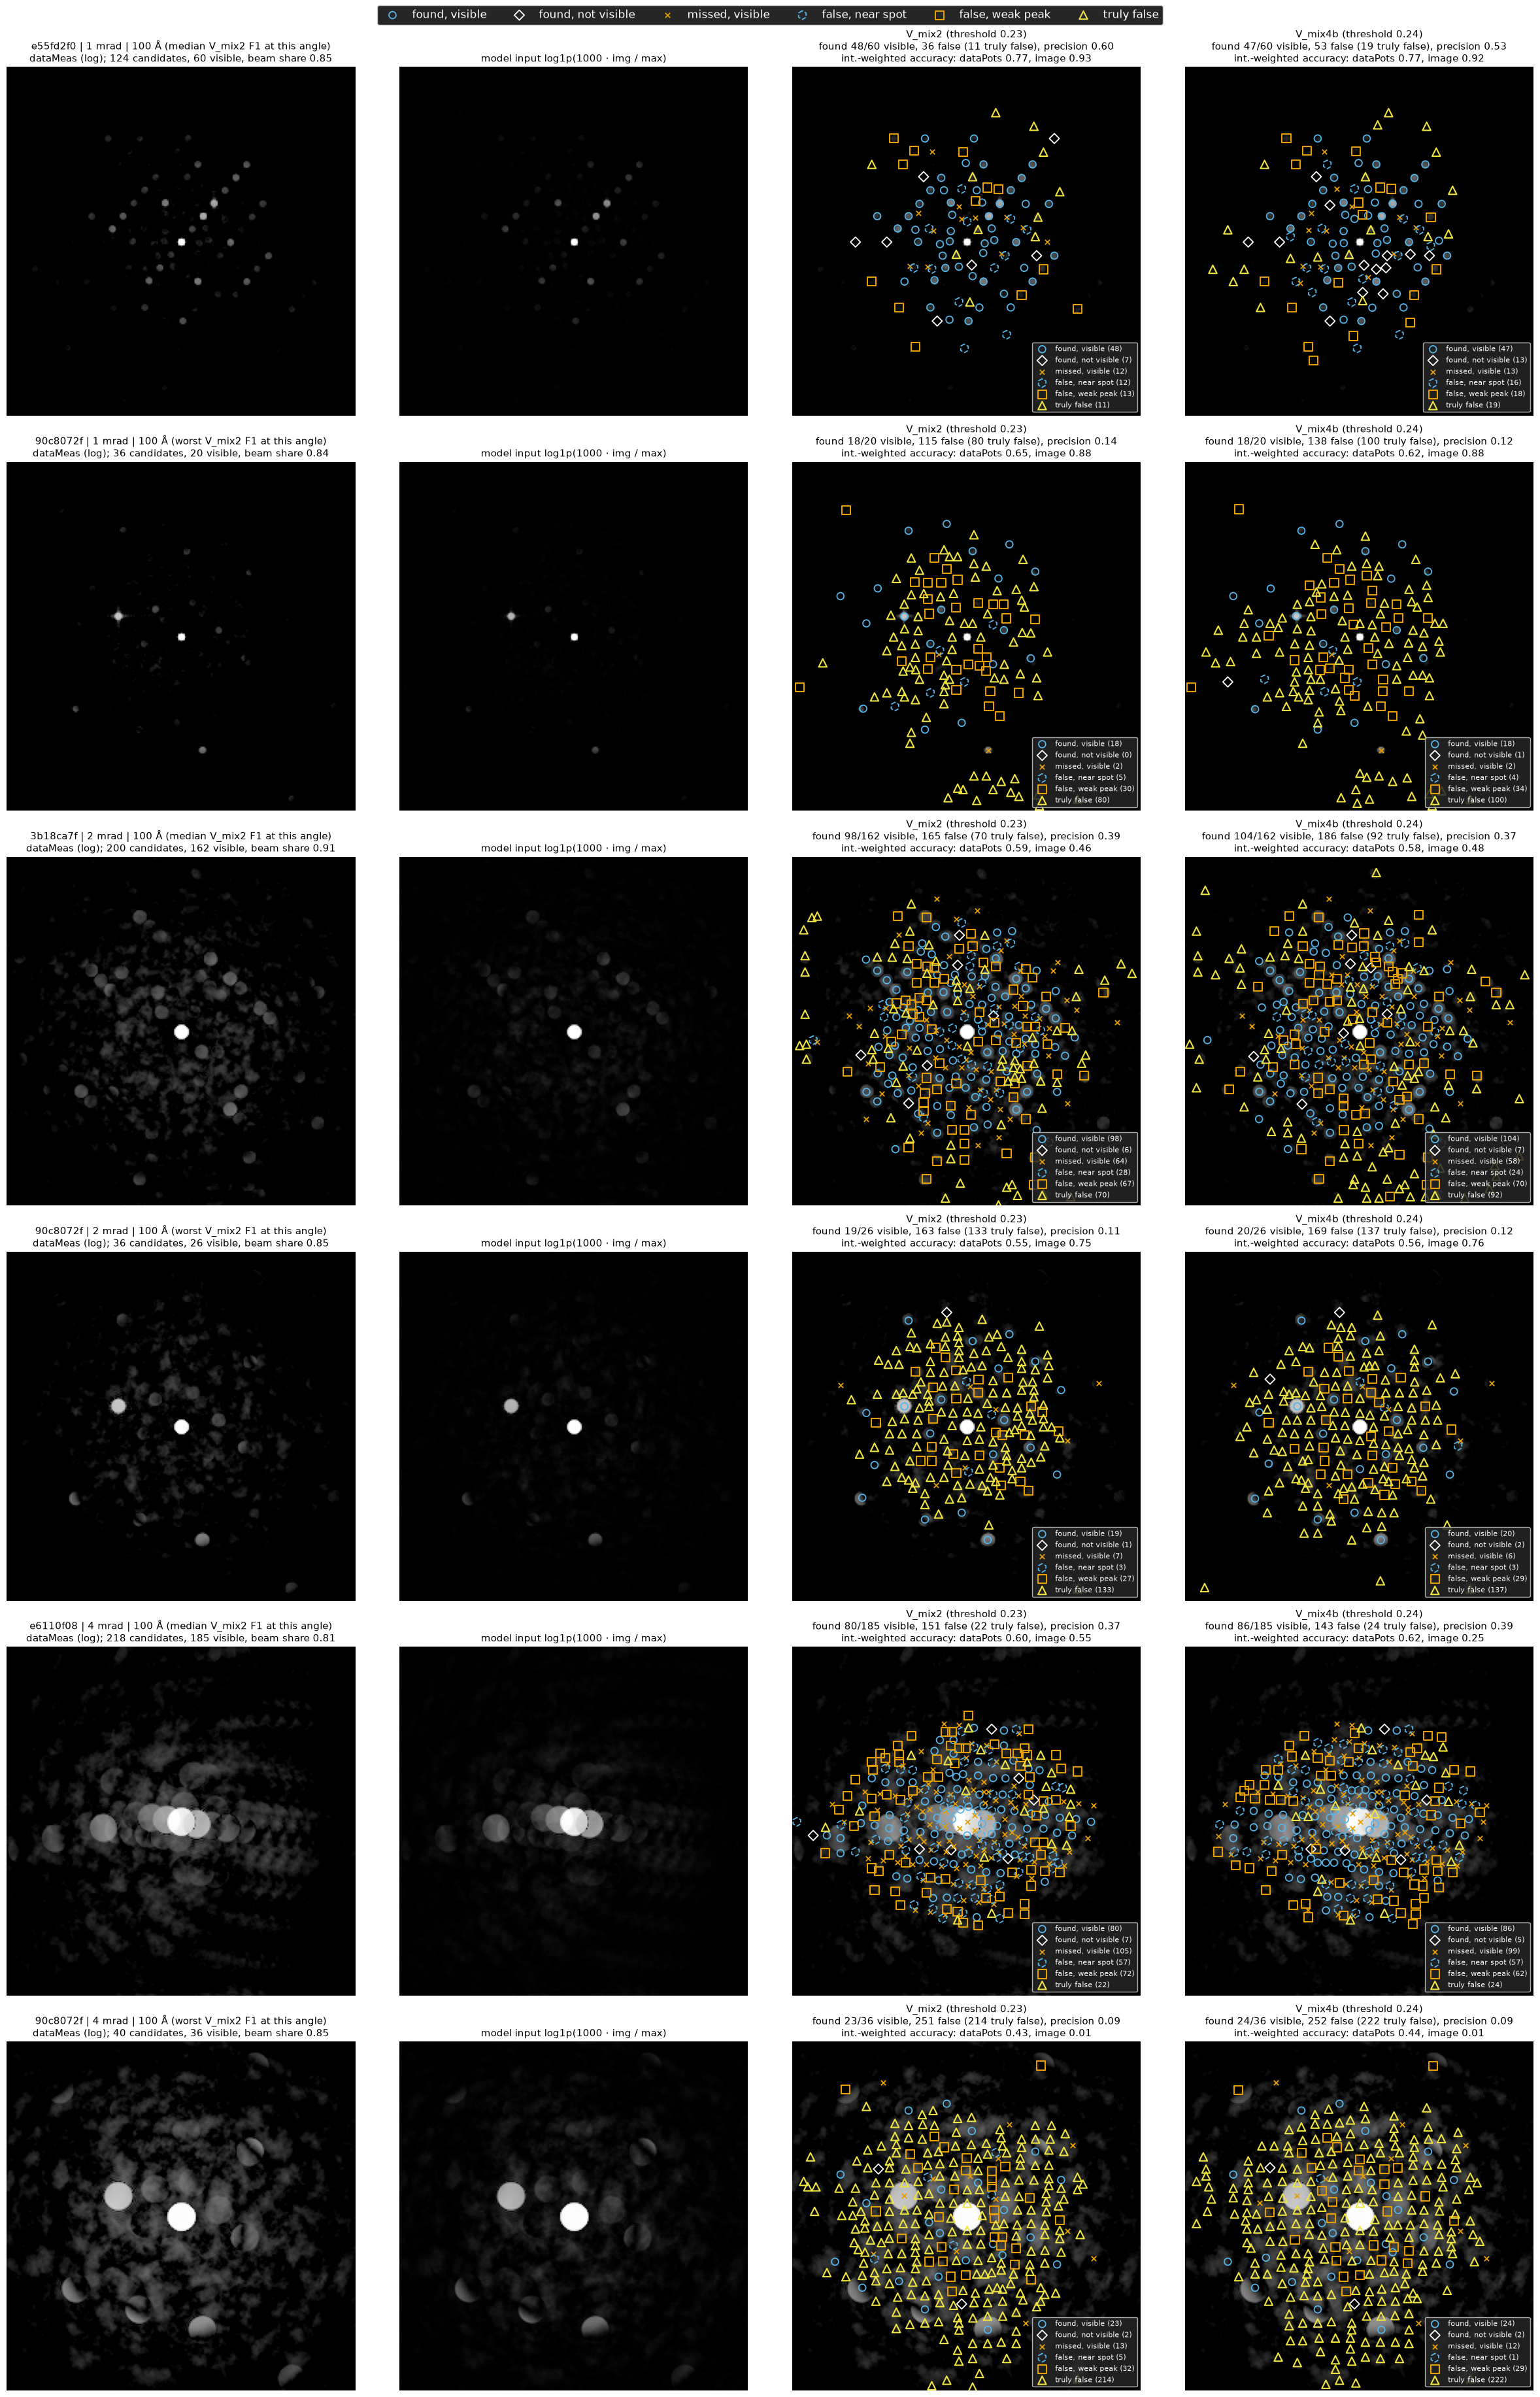

In [6]:
MARK = [
    ("found_vis", "found, visible", dict(s=60, marker="o", facecolors="none", edgecolors=SKY, linewidths=1.3)),
    ("found_inv", "found, not visible", dict(s=60, marker="D", facecolors="none", edgecolors="white", linewidths=1.3)),
    ("missed_vis", "missed, visible", dict(s=28, marker="x", c=ORANGE, linewidths=1.3)),
    ("fp_near", "false, near spot", dict(s=90, marker="h", facecolors="none", edgecolors=SKY, linewidths=1.3, linestyles="--")),
    ("fp_weak", "false, weak peak", dict(s=90, marker="s", facecolors="none", edgecolors=ORANGE, linewidths=1.5)),
    ("fp_false", "truly false", dict(s=80, marker="^", facecolors="none", edgecolors=YELLOW, linewidths=1.5)),
]


def categories(g, p):
    pts, vis = g["points"], g["visible"]
    p = np.asarray(p, float).reshape(-1, 2)
    p = p[bd.far_from(p, g["beam"], bd.BEAM_R)]
    m = points_matching(pts, p, cutoff_distance=bd.CUTOFF)
    gi = np.array([a for a, _ in m.matched_pairs], dtype=int)
    pj = np.array([b for _, b in m.matched_pairs], dtype=int)
    fp = np.array(sorted(m.false_positives), dtype=int)
    fn = np.array(sorted(m.false_negatives), dtype=int)
    m_off = points_matching(pts[fn].reshape(-1, 2), p[fp].reshape(-1, 2), cutoff_distance=bd.NEAR_R)
    near = fp[[b for _, b in m_off.matched_pairs]] if len(fp) else fp
    rest = fp[sorted(m_off.false_positives)] if len(fp) else fp
    m_weak = points_matching(g["weak"].reshape(-1, 2).astype(float), p[rest].reshape(-1, 2), cutoff_distance=bd.CUTOFF)
    weak = rest[[b for _, b in m_weak.matched_pairs]] if len(rest) else rest
    false = rest[sorted(m_weak.false_positives)] if len(rest) else rest
    vg = vis[gi] if len(gi) else np.zeros(0, bool)
    return dict(found_vis=p[pj[vg]] if len(pj) else p[:0], found_inv=p[pj[~vg]] if len(pj) else p[:0],
                missed_vis=pts[fn[vis[fn]]] if len(fn) else pts[:0], fp_near=p[near], fp_weak=p[weak], fp_false=p[false])


o100 = one[(one.model == "V_mix2") & (one.dataset == "new") & (one.thickness == 100)].copy()
P_ = 1 - o100["false"] / o100.n_pred.clip(lower=1)
R_ = o100.found_vis / o100.n_vis.clip(lower=1)
o100["f1"] = (2 * P_ * R_ / (P_ + R_)).fillna(0)
cases = []
for ang in (1.0, 2.0, 4.0):
    d = o100[o100.angle == ang].sort_values("f1")
    cases += [("median", d.iloc[len(d) // 2]), ("worst", d.iloc[0])]
fig, axs = plt.subplots(len(cases), 4, figsize=(24, 6.1 * len(cases)), layout="constrained")
fig.legend([plt.scatter([], [], **st) for *_, st in MARK], [s for _, s, _ in MARK], loc="outside upper center", ncol=6,
           fontsize=12, facecolor="0.15", labelcolor="white", framealpha=1)
for row, (kind, r) in zip(axs, cases):
    i = r.pattern
    img, pots, probe, g = load(i)
    x = bd.spotiflow_input(img, probe, "log", log_scale=S["log_scale"])
    nrm = LogNorm(vmin=g["floor"], vmax=img.max())
    row[0].imshow(img, cmap=GRAY, norm=nrm)
    row[0].set_title(f"{r.material} | {r.angle:g} mrad | 100 Å ({kind} V_mix2 F1 at this angle)\n"
                     f"dataMeas (log); {len(g['points'])} candidates, {int(g['visible'].sum())} visible, "
                     f"beam share {meta.loc[i, 'beam_share']:.2f}", fontsize=11)
    row[1].imshow(x, cmap=GRAY)
    row[1].set_title("model input log1p(1000 · img / max)", fontsize=11)
    for ax, k in zip(row[2:], ("V_mix2", "V_mix4b")):
        p = pred(k, i)
        s = bd.score(g, p)
        cat = categories(g, p)
        ax.imshow(img, cmap=GRAY, norm=nrm)
        for key, short, st in MARK:
            ax.scatter(cat[key][:, 1], cat[key][:, 0], label=f"{short} ({len(cat[key])})", **st)
        acc = one[(one.model == k) & (one.pattern == i)].iloc[0]
        ax.set_title(f"{k} (threshold {THR[k]:.2f})\nfound {s['found_vis']}/{s['n_vis']} visible, {s['false']} false "
                     f"({s['truly_false']} truly false), precision {s['precision']:.2f}\n"
                     f"int.-weighted accuracy: dataPots {acc.acc_pots:.2f}, image {acc.acc_img:.2f}", fontsize=11)
        ax.legend(loc="lower right", fontsize=8, facecolor="0.15", labelcolor="white", framealpha=0.85)
    for ax in row:
        ax.axis("off")
plt.show()

## 6. Comparison with py4DSTEM's FCU-Net

py4DSTEM includes a trained neural network for Bragg disks, the **FCU-Net** of Munshi et al. 2022 (npj Comput Mater
8:254, the paper of the intensity-weighted accuracy): `py4DSTEM.braggvectors.find_Bragg_disks_aiml`. It takes the
pattern and the vacuum probe and predicts the **potential image** (like `dataPots`); py4DSTEM's `get_maxima_2D` then
picks the peaks. It was run unchanged (`fcunet_sim93.py`, TensorFlow 2.15 + crystal4D, weights downloaded by py4DSTEM;
the average of 5 passes with Monte-Carlo dropout, as py4DSTEM recommends) on `dataMeas` and `dataProbe` of the same
1440 patterns. Our files have the same layout as its training data (`dataMeas`, `dataPots`, `dataProbe`), so no
conversion was needed.

Four methods, each tuned on the **31 validation materials** by the goal score (net found) and scored on the 62 test
materials and the old test against the same py4DSTEM ground truth (`score_fcunet_sim93.py`):

| method | what | tuned |
|---|---|---|
| V_mix2 | V_mix2 detections above a probability threshold | threshold |
| FCU-Net | peaks of the predicted potential | sigma (0, 0.5), minSpacing (2, 4, 6 px), relative cutoff (0.2–12 %) |
| V_mix2 AND FCU-Net | V_mix2 detections with an FCU-Net peak within 3 px (FCU-Net confirms) | threshold, cutoff |
| V_mix2 OR FCU-Net | V_mix2 detections plus FCU-Net peaks > 3 px from every V_mix2 detection | threshold, cutoff |

Tuning in two stages: a coarse grid (V_mix2 threshold in steps of 0.05, all FCU-Net settings and cutoffs), then the
**V_mix2 threshold in steps of 0.01** (alone: 0.05–0.65; AND / OR: 0.05–0.45 at the chosen FCU-Net cutoff and its two
grid neighbours). The plot after the table shows the fine stage.

In [7]:
fb = pd.read_csv(E / "fcunet_best.csv")
fin = pd.read_csv(E / "fcunet_final_patterns.csv")
best = fb[fb.part == "new test (62)"].set_index("method")
FC = {"V_mix2": ("V_mix2", PINK, "D", ""), "fcunet": ("FCU-Net", BLUE, "o", "//"),
      "V_mix2 AND fc": ("V_mix2 AND FCU-Net", ORANGE, "s", ".."), "V_mix2 OR fc": ("V_mix2 OR FCU-Net", SKY, "^", "xx")}
ORDER = list(FC)


def fc_setting(r):
    out = []
    if pd.notna(r.t):
        out.append(f"threshold {r.t:.2f}")
    if isinstance(r.setting, str) and r.setting:
        sg, ms = r.setting[1:].split("_m")
        out.append(f"sigma {sg}, minSpacing {ms}, cutoff {100 * r.cut:g} %")
    return "; ".join(out)


tab = fb[fb.part != "new validation (31)"].copy()
tab["settings"] = tab.apply(fc_setting, axis=1)
tab["method"] = pd.Categorical(tab.method, ORDER)
tab = tab.sort_values(["part", "method"]).assign(method=lambda d: d.method.map({k: v[0] for k, v in FC.items()}))
show = tab.set_index(["part", "method"])[["settings", "recall", "truly_false", "truly_false_share", "net_found", "f1",
                                          "acc_pots", "acc_img", "found", "visible"]]
display(show.style.format({c: "{:.3f}" for c in ["recall", "truly_false_share", "net_found", "f1", "acc_pots", "acc_img"]}
                          | {c: "{:,.0f}" for c in ["truly_false", "found", "visible"]}))

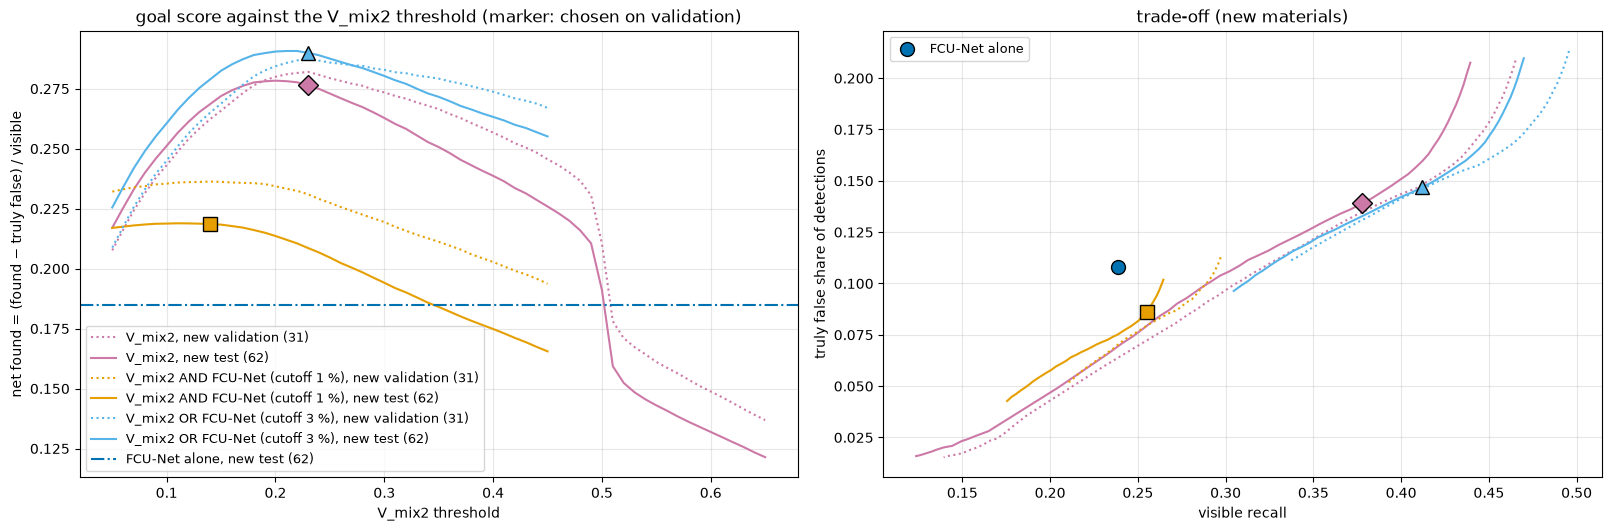

chosen V_mix2 thresholds: {'V_mix2': 0.23, 'V_mix2 AND fc': 0.14, 'V_mix2 OR fc': 0.23}


In [8]:
sf = pd.read_csv(E / "fcunet_sweep_fine.csv.gz", keep_default_na=False, na_values=[""], dtype={"setting": str})
cols = ["n_vis", "found_vis", "n_pred", "false", "truly_false", "false_on_weak_peak", "false_near_spot"]
fig, axs = plt.subplots(1, 2, figsize=(16, 5.2), layout="constrained")
for k in ["V_mix2", "V_mix2 AND fc", "V_mix2 OR fc"]:
    name, c, mk, _ = FC[k]
    bk = best[best.index == k].iloc[0] if k in best.index else None
    d = sf[sf.method == k]
    if k != "V_mix2":
        d = d[np.isclose(d.cut, bk.cut)]
    for part, ls in (("new validation (31)", ":"), ("new test (62)", "-")):
        cv = d[d.part == part].groupby("t")[cols].sum()
        net = (cv.found_vis - cv.truly_false) / cv.n_vis
        lab = f"{name}" + (f" (cutoff {100 * bk.cut:g} %)" if k != "V_mix2" else "") + f", {part}"
        axs[0].plot(net.index, net, ls=ls, color=c, label=lab)
        axs[1].plot(cv.found_vis / cv.n_vis, cv.truly_false / cv.n_pred, ls=ls, color=c)
        if part == "new test (62)":
            axs[0].plot(bk.t, net.loc[round(bk.t, 2)], mk, color=c, ms=10, mec="black")
            axs[1].plot(cv.found_vis.loc[round(bk.t, 2)] / cv.n_vis.loc[round(bk.t, 2)],
                        cv.truly_false.loc[round(bk.t, 2)] / cv.n_pred.loc[round(bk.t, 2)], mk, color=c, ms=10, mec="black")
fr = best.loc["fcunet"]
axs[0].axhline(fr.net_found, color=BLUE, lw=1.5, ls="-.", label="FCU-Net alone, new test (62)")
axs[1].plot(fr.recall, fr.truly_false_share, "o", color=BLUE, ms=10, mec="black", label="FCU-Net alone")
axs[0].set(xlabel="V_mix2 threshold", ylabel="net found = (found − truly false) / visible",
           title="goal score against the V_mix2 threshold (marker: chosen on validation)")
axs[1].set(xlabel="visible recall", ylabel="truly false share of detections", title="trade-off (new materials)")
axs[0].legend(fontsize=9); axs[1].legend(fontsize=9)
for ax in axs:
    ax.grid(alpha=0.3)
plt.show()
print("chosen V_mix2 thresholds:", best["t"].dropna().to_dict())

### 6.1 By probe angle and thickness (62 new test materials)

Bars per method (colour and hatch); rows: recall of visible spots, share of detections that are truly false, net
found, intensity-weighted accuracy with `dataPots` weights.

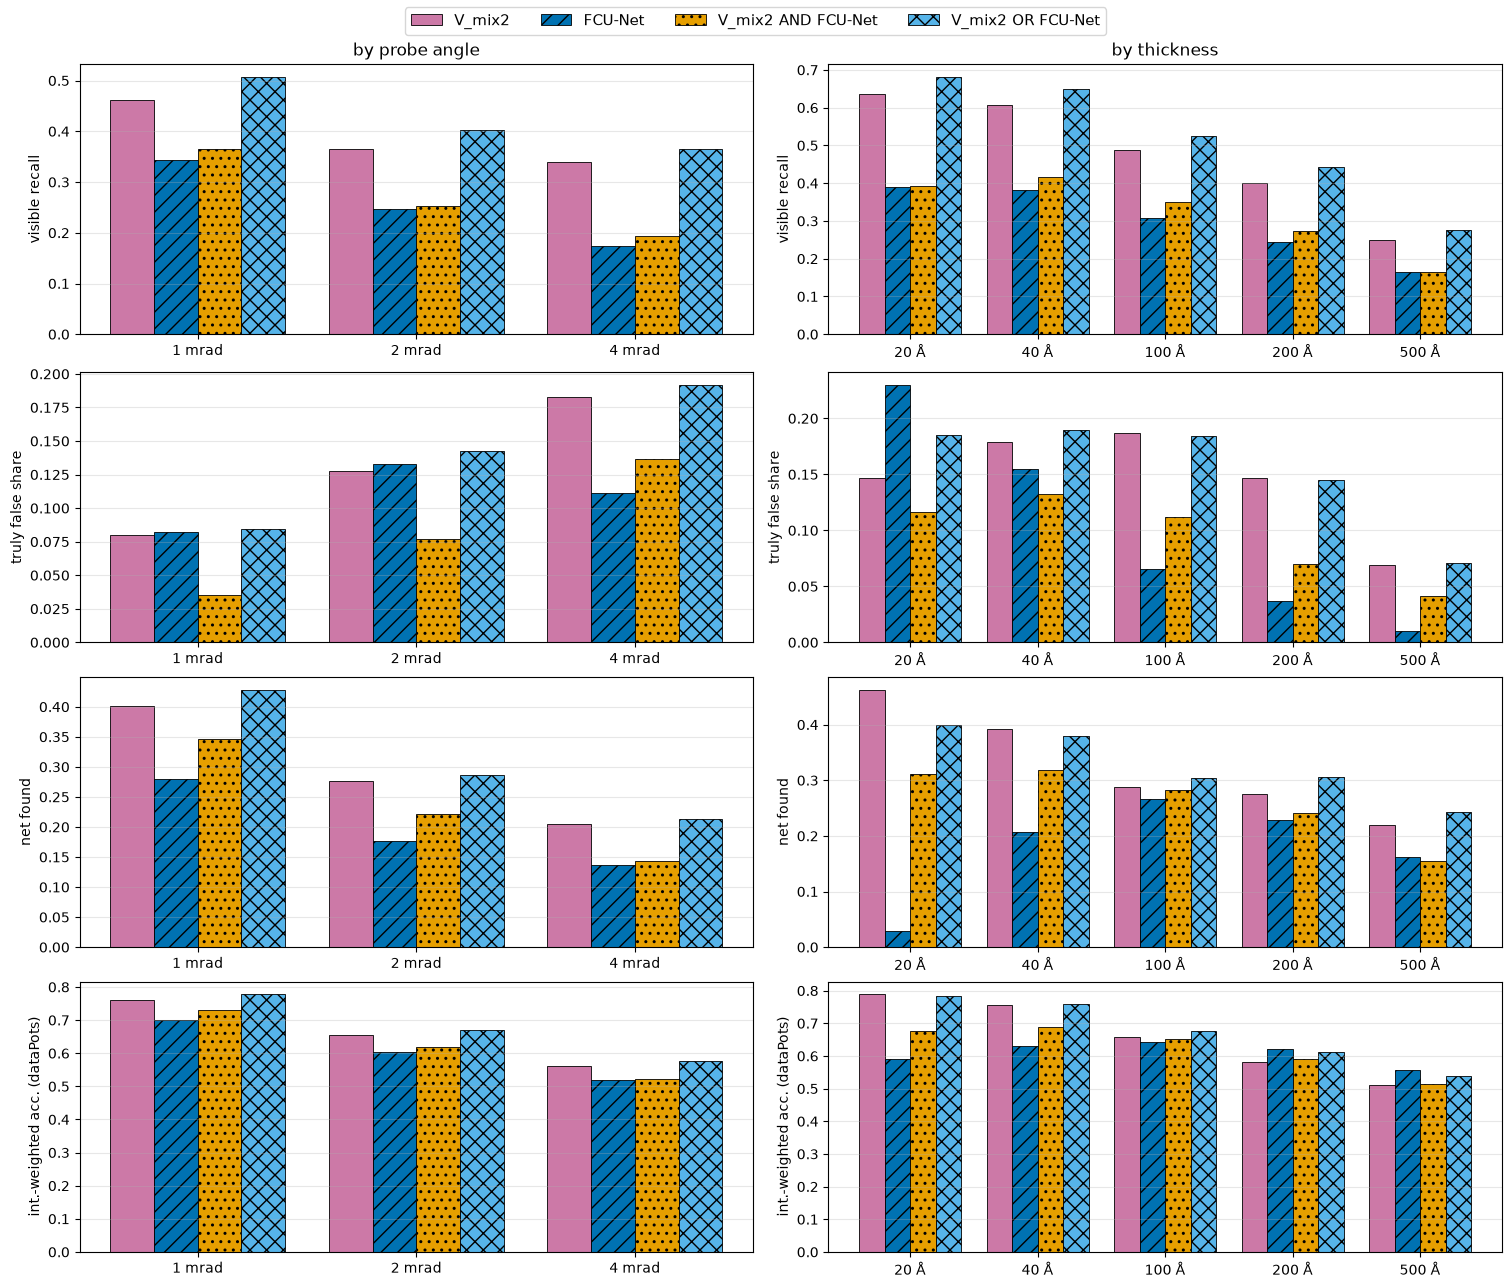

In [9]:
ft = fin[fin.part == "new test (62)"]
METRICS = [("recall", "visible recall"), ("truly_false_share", "truly false share"), ("net_found", "net found"),
           ("acc_pots", "int.-weighted acc. (dataPots)")]
fig, axs = plt.subplots(len(METRICS), 2, figsize=(15, 3.2 * len(METRICS)), layout="constrained")
for col, by in enumerate(["angle", "thickness"]):
    g = ft.groupby(["method", by]).apply(pooled)
    xs = sorted(ft[by].unique())
    for row, (m, lab) in enumerate(METRICS):
        ax = axs[row, col]
        for j, k in enumerate(ORDER):
            name, c, mk, h = FC[k]
            v = [g.loc[(k, x), m] for x in xs]
            ax.bar(np.arange(len(xs)) + (j - 1.5) * 0.2, v, 0.2, color=c, hatch=h, edgecolor="black", lw=0.6,
                   label=name)
        ax.set_xticks(range(len(xs)), [f"{x:g} mrad" if by == "angle" else f"{x:g} Å" for x in xs])
        ax.set_ylabel(lab)
        ax.grid(axis="y", alpha=0.3)
fig.legend(*axs[0, 0].get_legend_handles_labels(), ncol=4, loc="outside upper center", fontsize=11)
axs[0, 0].set_title("by probe angle")
axs[0, 1].set_title("by thickness")
plt.show()

### 6.2 Examples

New test materials at 100 Å: for each angle the material with the median V_mix2 F1 (as in section 5), and
90c8072f at 4 mrad (big separate disks; the brightest disk is missed by V_mix2). Columns: true potential `dataPots`,
FCU-Net's predicted potential (both log, from 10⁻⁴ of the maximum, with the visible ground-truth spots as circles),
then FCU-Net's peaks and V_mix2's detections (the settings of the table) on `dataMeas` with the markers of section 5.

**All four columns show the same pattern** (same material, angle and thickness); they look different because they are
different images of it. The potentials (columns 1–2) have one sharp point per reflection and are shown down to 10⁻⁴
of their maximum, so the whole field is grey. The measured pattern `dataMeas` (columns 3–4) has a disk of the probe
size at each reflection (large at 4 mrad) and is shown from the visibility floor, so its faint background is black.
The same circles lie on the points of columns 1–2 and on the disks of columns 3–4.

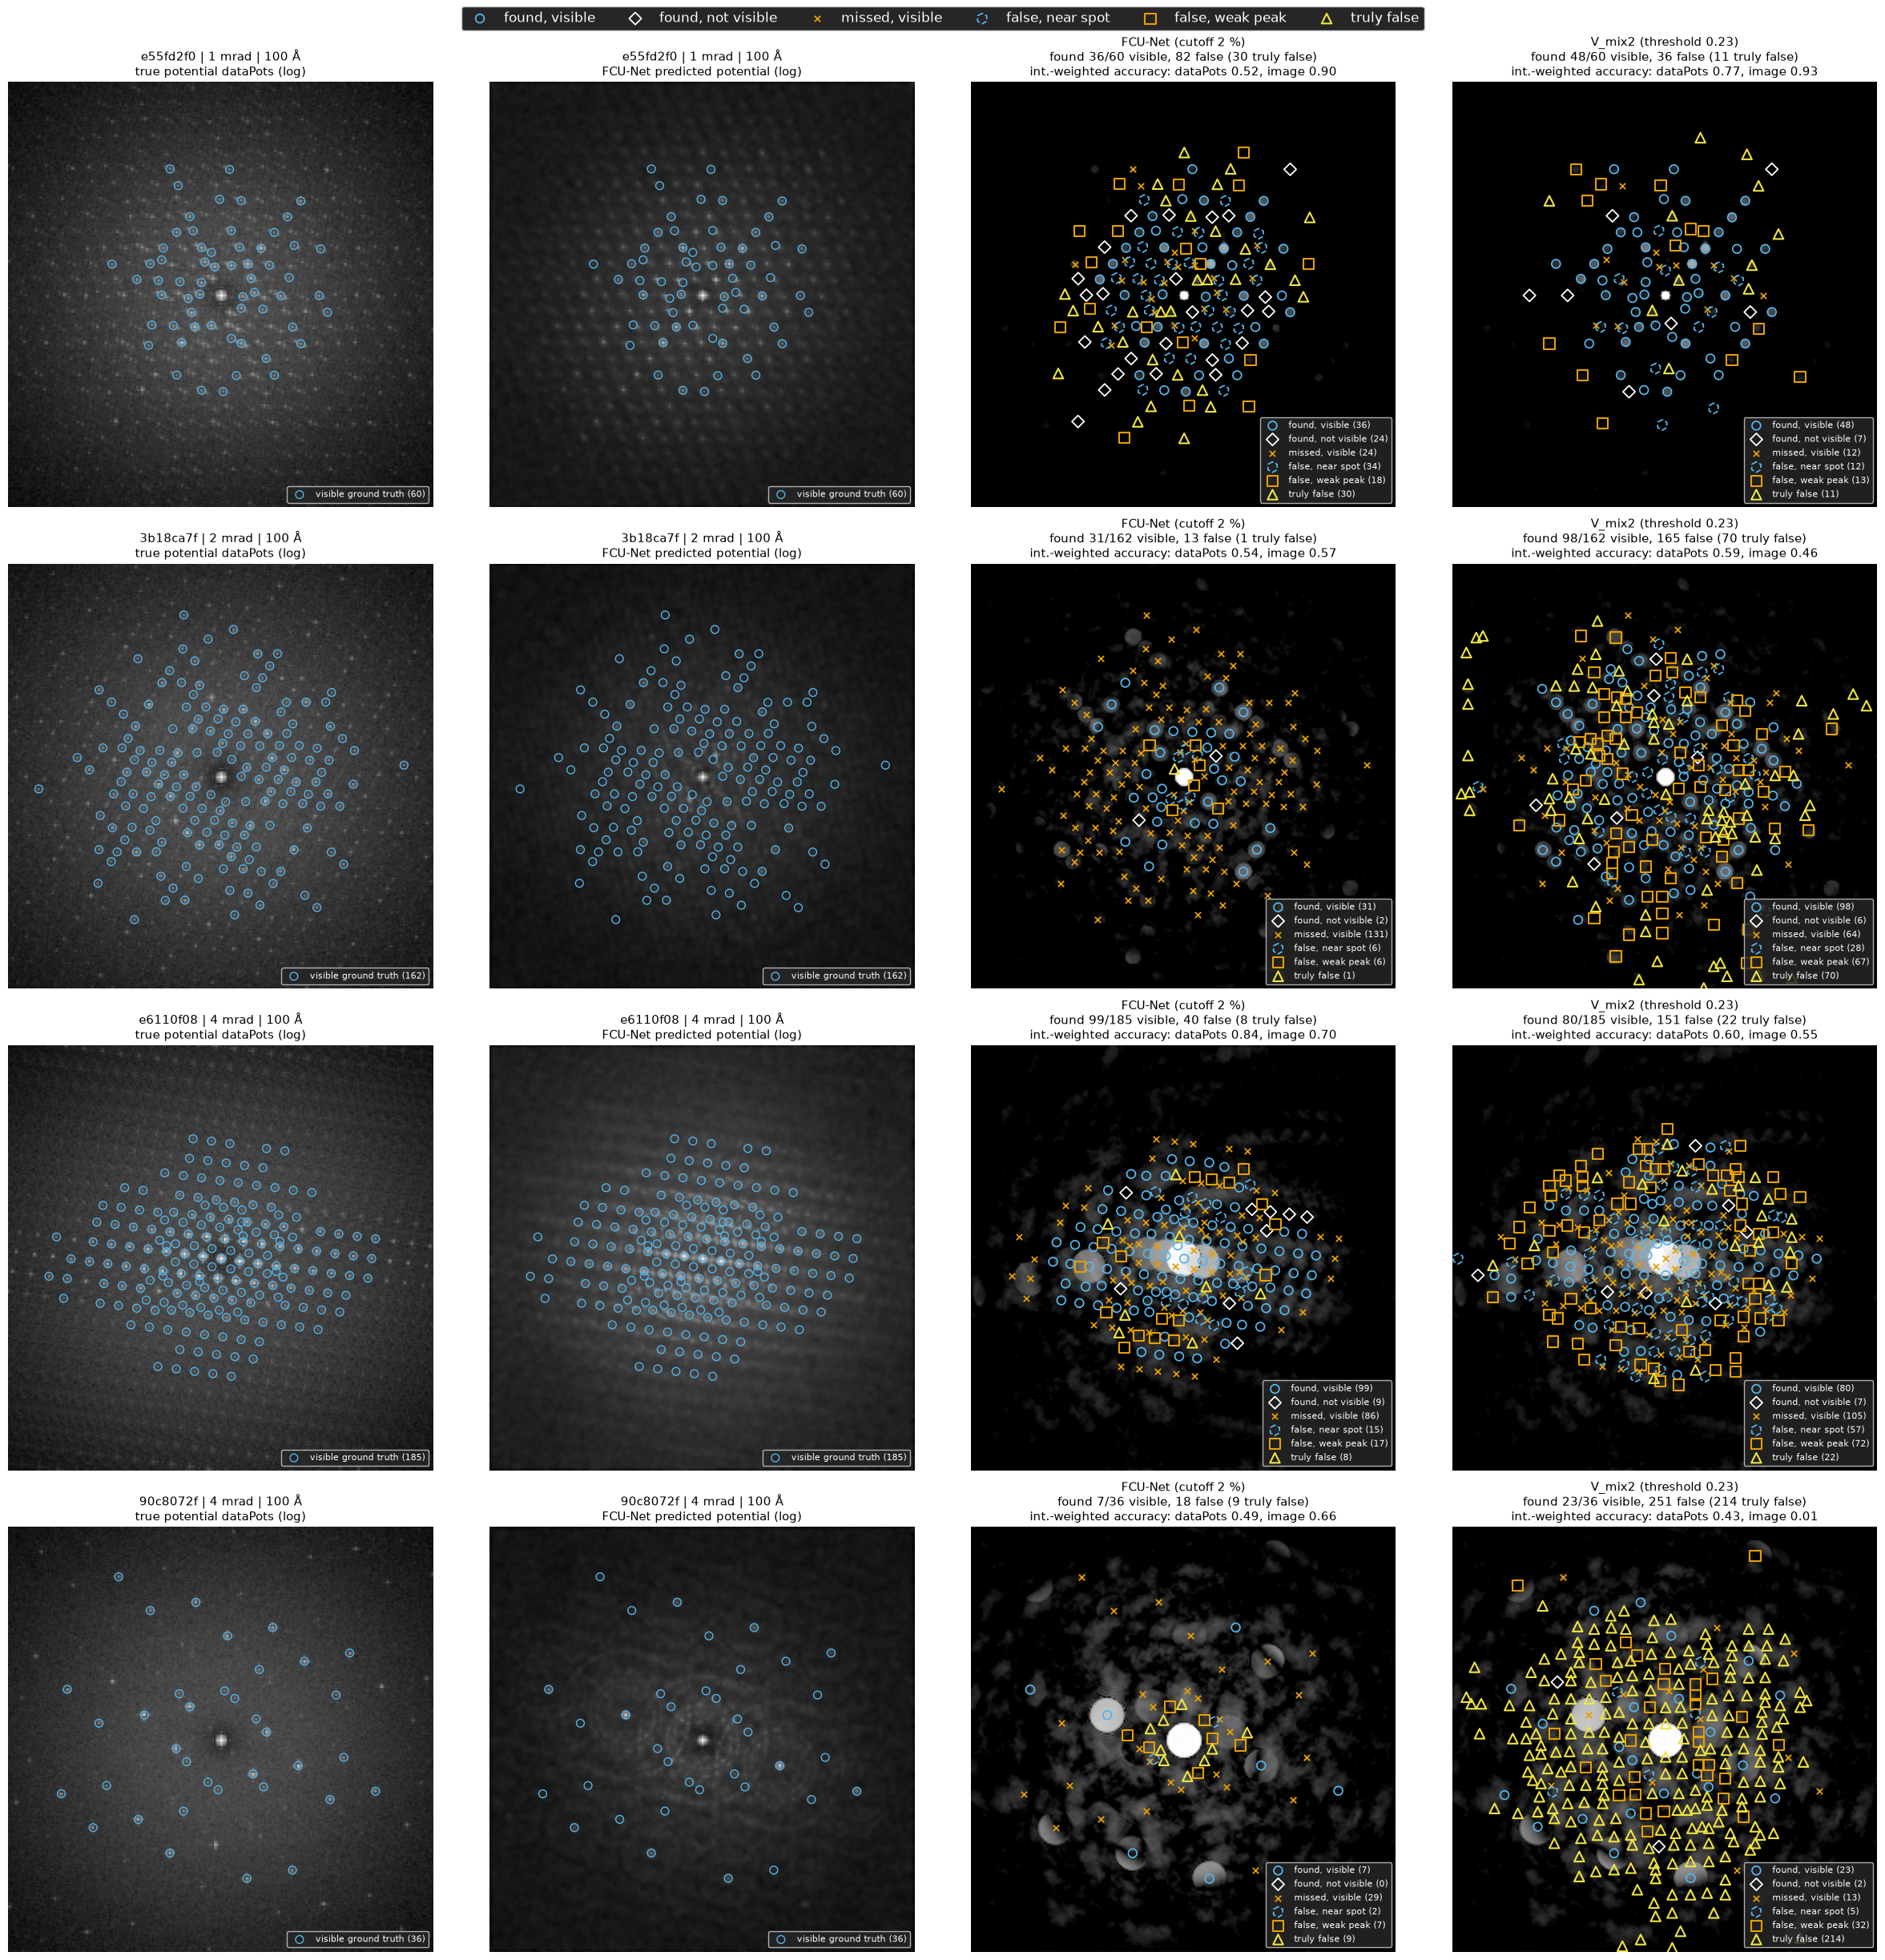

In [10]:
FCP = np.load("/mnt/data/fcunet/fcunet_peaks.npz")
FCPOT = np.load("/mnt/data/fcunet/pred_pots.npy", mmap_mode="r")
best = fb[fb.part == "new test (62)"].set_index("method")
fc_set, fc_cut, vm_t = best.loc["fcunet", "setting"], best.loc["fcunet", "cut"], best.loc["V_mix2", "t"]


def fc_pred(i):
    p, rel = FCP[f"{fc_set}_{i}_pts"], FCP[f"{fc_set}_{i}_rel"]
    return p[rel >= fc_cut]


ex = [r.pattern for kind, r in cases if kind == "median"] + [732]
fig, axs = plt.subplots(len(ex), 4, figsize=(24, 6.1 * len(ex)), layout="constrained")
fig.legend([plt.scatter([], [], **st) for *_, st in MARK], [s for _, s, _ in MARK], loc="outside upper center", ncol=6,
           fontsize=12, facecolor="0.15", labelcolor="white", framealpha=1)
for row, i in zip(axs, ex):
    r = meta.loc[i]
    img, pots, probe, g = load(i)
    fp = np.asarray(FCPOT[i], np.float32)
    for ax, im, name in ((row[0], pots, "true potential dataPots"), (row[1], fp, "FCU-Net predicted potential")):
        ax.imshow(np.clip(im, im.max() * 1e-4, None), cmap=GRAY, norm=LogNorm())
        ax.set_title(f"{r.material} | {r.angle:g} mrad | {r.thickness:g} Å\n{name} (log)", fontsize=11)
    for ax in row[:2]:
        ax.scatter(g["points"][g["visible"], 1], g["points"][g["visible"], 0], s=50, facecolors="none",
                   edgecolors=SKY, lw=1, label=f"visible ground truth ({int(g['visible'].sum())})")
        ax.legend(loc="lower right", fontsize=8, facecolor="0.15", labelcolor="white", framealpha=0.85)
    nrm = LogNorm(vmin=g["floor"], vmax=img.max())
    for ax, name, p in ((row[2], f"FCU-Net (cutoff {100 * fc_cut:g} %)", fc_pred(i)),
                        (row[3], f"V_mix2 (threshold {vm_t:.2f})", pred("V_mix2", i, vm_t))):
        s = bd.score(g, p)
        cat = categories(g, p)
        ax.imshow(img, cmap=GRAY, norm=nrm)
        for key, short, st in MARK:
            ax.scatter(cat[key][:, 1], cat[key][:, 0], label=f"{short} ({len(cat[key])})", **st)
        a_p = weighted_accuracy(pots, g["points"], p, g["beam"], gt_required=g["visible"])["accuracy"]
        a_i = weighted_accuracy(img, g["points"], p, g["beam"], gt_required=g["visible"])["accuracy"]
        ax.set_title(f"{name}\nfound {s['found_vis']}/{s['n_vis']} visible, {s['false']} false "
                     f"({s['truly_false']} truly false)\nint.-weighted accuracy: dataPots {a_p:.2f}, image {a_i:.2f}",
                     fontsize=11)
        ax.legend(loc="lower right", fontsize=8, facecolor="0.15", labelcolor="white", framealpha=0.85)
    for ax in row:
        ax.axis("off")
plt.show()

## Results

All scores against the **py4DSTEM ground truth** (`get_maxima_2D` on `dataPots`, sigma 0.5, 2 %, no peak cap).
Thresholds chosen on the 31 new validation materials; scores on the **62 new test materials** (930 patterns) and the
3 old test materials (45 patterns).

**Thresholds for the goal** (most visible spots, few truly false ones; largest *net found* = (found − truly false) /
visible): **V 0.19, V_mix2 0.23, V_mix4b 0.24** (F1 rule: 0.17, 0.18, 0.20; usual: 0.572, 0.48, 0.46).

| set | model | rule (threshold) | visible recall | truly false (share of detections) | net found | F1 | int.-w. acc. dataPots | int.-w. acc. image |
|---|---|---|---|---|---|---|---|---|
| new test (62) | V | **goal (0.19)** | 0.407 | 24,045 (12.7 %) | **0.306** | 0.473 | 0.667 | 0.515 |
| | | usual (0.572) | 0.140 | 481 (1.3 %) | 0.138 | 0.242 | 0.639 | 0.658 |
| | V_mix2 | **goal (0.23)** | 0.378 | 23,980 (13.9 %) | **0.276** | 0.450 | 0.659 | 0.587 |
| | | usual (0.48) | 0.241 | 5,924 (7.1 %) | 0.216 | 0.361 | 0.665 | 0.619 |
| | V_mix4b | **goal (0.24)** | 0.382 | 26,366 (14.4 %) | **0.270** | 0.449 | 0.655 | 0.590 |
| old test (3) | V | goal (0.19) | 0.641 | 1,914 (18.9 %) | 0.426 | 0.641 | 0.872 | 0.702 |
| | V_mix2 | goal (0.23) | 0.648 | 858 (10.5 %) | 0.552 | 0.704 | 0.891 | 0.820 |
| | V_mix4b | goal (0.24) | 0.639 | 836 (10.3 %) | 0.545 | 0.701 | 0.893 | 0.810 |

1. **With the py4DSTEM ground truth the goal thresholds are low (0.19–0.24).** The py4DSTEM labels (sigma 0.5) contain
   about a third more visible spots than the earlier skimage labels, many of them weak spots inside a neighbour's
   disk at 2 and 4 mrad, so finding them pays for some truly false detections. Against the usual thresholds
   (0.46–0.57, chosen on experimental patterns) the goal threshold finds 1.6× (V_mix2) to 2.9× (V) more visible spots;
   the truly false share rises from 1–7 % to 13–14 %.
2. **On the new materials the three models are close.** V has the highest net found (0.306), V_mix2 0.276, V_mix4b
   0.270; on the old test V_mix2 is clearly best (0.552 vs 0.426 for V, whose truly false share is 19 %). For use on
   both, V_mix2 at 0.23 stays the best compromise.
3. **The new materials are much harder.** At the goal threshold V_mix2 finds 38 % of the visible spots of the new test
   materials (old test 65 %), with intensity-weighted accuracy 0.66 vs 0.89 (`dataPots` weights). It is not a label
   problem: the labels lie on the spots (median offset 0.00 px, no flip or transpose).
4. **Thickness and probe angle matter most** (section 2; V_mix2, new test): recall 0.64 at 20 Å → 0.25 at 500 Å, and
   0.46 at 1 mrad → 0.34 at 4 mrad, where 18 % of detections are truly false (1 mrad: 8 %). Intensity-weighted
   accuracy (`dataPots`) falls from 0.79 (20 Å) to 0.51 (500 Å) and from 0.76 (1 mrad) to 0.56 (4 mrad). The
   image-weighted version drops to 0.35 at 4 mrad because the spots next to the direct beam take up the beam's light
   in their 3 × 3 maximum; read the `dataPots` version.
5. **py4DSTEM's FCU-Net is weaker than V_mix2** (section 6; every setting chosen on the validation materials, the
   V_mix2 threshold in steps of 0.01):

   | 62 new test materials | recall | truly false share | net found | F1 | acc. dataPots | acc. image |
   |---|---|---|---|---|---|---|
   | V_mix2 (threshold 0.23) | 0.378 | 13.9 % | 0.276 | 0.450 | 0.659 | 0.587 |
   | FCU-Net (sigma 0, minSpacing 6, cutoff 2 %) | 0.239 | 10.8 % | 0.185 | 0.346 | 0.608 | 0.572 |
   | V_mix2 AND FCU-Net (threshold 0.14, cutoff 1 %) | 0.255 | 8.6 % | 0.219 | 0.367 | 0.624 | 0.586 |
   | V_mix2 OR FCU-Net (threshold 0.23, cutoff 3 %) | 0.412 | 14.7 % | 0.290 | 0.474 | 0.675 | 0.573 |

   The fine tuning gives V_mix2 the same threshold as its goal threshold above (0.23); the combinations change little
   from the coarse grid (AND 0.15 → 0.14, OR 0.25 → 0.23). FCU-Net alone finds 63 % as many visible spots as V_mix2
   and is behind at every angle and thickness (4 mrad recall 0.17 vs 0.34); on the old test it reaches net found 0.31
   vs 0.55, with 23 % truly false detections. Requiring FCU-Net to confirm a V_mix2 detection (AND) removes 64 % of
   the truly false detections but also 32 % of the found spots. Adding FCU-Net's extra peaks (OR) gains +0.014 net
   found and +0.016 accuracy on the new test materials but is worse on the old test (net found 0.48 vs 0.55, truly
   false share 18 % vs 10 %), so it is not worth the second network. Our files have the same layout as FCU-Net's
   training data, so it may even have seen similar materials, which would favour it.
   FCU-Net does have strengths: it has fewer truly false detections at 200–500 Å (4 % and 1 % vs 15 % and 7 %) and
   a better intensity-weighted accuracy there. In the examples (6.2) it beats V_mix2 on the dense 4 mrad lattice
   e6110f08 (99 vs 80 of 185 visible spots found, 8 vs 22 truly false). On 90c8072f it puts 9 truly false
   detections instead of V_mix2's 214 on the diffuse background, but finds only 7 of the 36 visible spots (V_mix2: 23).

**Conclusion.** For the goal use **V_mix2 at 0.23**. Neither the threshold, the training-free post-processing (the
lattice filter helps a little) nor py4DSTEM's FCU-Net closes the gap on the new materials: the models have learned the
24 training crystals rather than Bragg disks in general. The next step is to train V2 on more materials (the 24 old +
the new ones), keeping the 62 new test materials unseen; this notebook's scores are the zero-shot baseline (V_mix2:
net found 0.28, recall 0.38 with 14 % truly false, intensity-weighted accuracy 0.66).
